# DATASCI 530 – Assignment 2

**Parimal Majumder**

## Formula 1 Constructor and Driver Analysis

## Summary of Findings

This analysis examines Formula 1 constructor performance across two time periods, 1981–2020 and 2001–2020, and evaluates Ferrari's drivers and yearly performance.

*** The key findings will be summarized at the end of this analysis.***

## 1. Setup and Data Import

The Formula 1 datasets are stored in the `data_raw` folder. 
We first import the Python libraries needed for the analysis and then load the relevant datasets.

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [56]:
# Datasets loaded here

races = pd.read_csv("data_raw/races.csv")
results = pd.read_csv("data_raw/results.csv")
constructors = pd.read_csv("data_raw/constructors.csv")
drivers = pd.read_csv("data_raw/drivers.csv")

## 2. Data Inspection as assignment asked for

Inspected their dimensions and column names to identify the variables needed for the analysis. 
Also needed quality checks, including checking missing values for key variables.


In [57]:
races.shape
races.columns
results.shape
results.columns
constructors.shape
constructors.columns
drivers.shape
drivers.columns

Index(['driverId', 'driverRef', 'number', 'code', 'forename', 'surname', 'dob',
       'nationality', 'url'],
      dtype='str')

### Is there any missing value in all four datasets?

In [58]:
races[["raceId", "year"]].isna().sum()
results[["raceId", "driverId", "constructorId", "points"]].isna().sum()
constructors[["constructorId", "name"]].isna().sum()
drivers[["driverId", "forename", "surname"]].isna().sum()

driverId    0
forename    0
surname     0
dtype: int64

### Data Quality Check
No missing values were found in the selected variables from the races, results, 
constructors, or drivers datasets.

In [59]:
# The first merge should be results with the two useful columns from races:
results_races = pd.merge(
    results,
    races[["raceId", "year"]],
    on="raceId",
    how="left"
)
results_races.head
results_races.tail

<bound method NDFrame.tail of        resultId  raceId  driverId  constructorId number  grid position  \
0             1      18         1              1     22     1        1   
1             2      18         2              2      3     5        2   
2             3      18         3              3      7     7        3   
3             4      18         4              4      5    11        4   
4             5      18         5              1     23     3        5   
...         ...     ...       ...            ...    ...   ...      ...   
25835     25841    1096       854            210     47    12       16   
25836     25842    1096       825            210     20    16       17   
25837     25843    1096         1            131     44     5       18   
25838     25844    1096       849              3      6    20       19   
25839     25845    1096         4            214     14    10       \N   

      positionText  positionOrder  points  laps         time milliseconds  \
0   

In [60]:
races[["raceId", "year"]]
results_races.shape
# looks like we successfully bring the years in the merged dataset. 19 columns after merged 

(25840, 19)

In [61]:
# add the constructor name

results_races_constructors = pd.merge(
    results_races,
    constructors[["constructorId", "name"]],
    on="constructorId",
    how="left"
)
results_races_constructors = pd.merge(
    results_races,
    constructors[["constructorId", "name"]],
    on="constructorId",
    how="left"
)
results_races_constructors
results_races_constructors.shape
results_races_constructors[["raceId", "year", "constructorId", "name", "points"]].head()

,raceId,year,constructorId,name,points
0,18,2008,1,McLaren,10.0
1,18,2008,2,BMW Sauber,8.0
2,18,2008,3,Williams,6.0
3,18,2008,4,Renault,5.0
4,18,2008,1,McLaren,4.0


## 3. Constructor Performance, 1981–2020
### Questions according to the assignement

a) Which three constructors earned the most points between 1981 and 2020? How many
total points did each of them earn? How do the total points for each constructor
compare with the average across constructors?

To identify the highest-performing constructors, the merged dataset is restricted 
to races from 1981 through 2020. Points are then summed for each constructor.

In [62]:
# Filter the year (1981-2020)

period_1981_2020 = results_races_constructors[
    results_races_constructors["year"].between(1981, 2020) 
]
period_1981_2020["year"] # confirmed the year range
period_1981_2020["year"].min(), period_1981_2020["year"].max()

(np.int64(1981), np.int64(2020))

In [63]:
# Calculate the total points for each constructor

constructor_points_1981_2020 = (
    period_1981_2020
    .groupby("name")["points"]
    .sum()
    .reset_index()
)
constructor_points_1981_2020.head()

,name,points
0,AGS,2.0
1,ATS,5.0
2,Alfa Romeo,111.0
3,AlphaTauri,107.0
4,Andrea Moda,0.0


In [64]:
# Top 3 Constructors with highest point

top3_1981_2020 = (
    constructor_points_1981_2020
    .sort_values("points", ascending=False)
    .head(3)
)
top3_1981_2020

,name,points
16,Ferrari,7374.0
40,Mercedes,5685.0
39,McLaren,5229.5


In [65]:
# Total points for each constructor compare with the average across constructors

average_points_1981_2020 = constructor_points_1981_2020["points"].mean()
average_points_1981_2020

np.float64(532.2388059701492)

In [66]:
# Lets compare with average ... how many points above the average

top3_1981_2020["above_average"] = (
    top3_1981_2020["points"] - average_points_1981_2020
)

top3_1981_2020

,name,points,above_average
16,Ferrari,7374.0,6841.761194
40,Mercedes,5685.0,5152.761194
39,McLaren,5229.5,4697.261194


In [67]:
# Table with round number which can be a publication quality table 

table_1981_2020 = (
    top3_1981_2020
    .rename(columns={
        "name": "Constructor",
        "points": "Total Points",
        "above_average": "Points Above Average"
    })
    .round(2)
    .reset_index(drop=True)
)
table_1981_2020

,Constructor,Total Points,Points Above Average
0,Ferrari,7374.0,6841.76
1,Mercedes,5685.0,5152.76
2,McLaren,5229.5,4697.26


### Findings for 1981–2020

Between the years from 1981 to 2020, Ferrari won the champhionship as earned the most points with 7,374 points. Mercedes stood 2nd with 5,685 points and then McLaren became 3rd position ranked with 5,229.5 points.

The average total across all constructors was approximately 532.24 points. Ferrari earned 6,841.76 points above this average, Mercedes earned 5,152.76 points above the average, and McLaren earned 4,697.26 points above the average.

## 4. Constructor Performance, 2001–2020

### Question in the assignement

b) Which three constructors earned the most points between 2001 and 2020? How many
total points did each of them earn? How do the total points for each constructor
compare with the average across constructors?

In [68]:
# Filtered the data (2001-2020)

period_2001_2020 = results_races_constructors[
    results_races_constructors["year"].between(2001, 2020)
]
period_2001_2020
period_2001_2020["year"].min(), period_2001_2020["year"].max() # verify the year range 

(np.int64(2001), np.int64(2020))

In [69]:
# Total points earned 

constructor_points_2001_2020 = (
    period_2001_2020
    .groupby("name")["points"]
    .sum()
    .reset_index()
)

In [70]:
# Top 3 points 

top3_2001_2020 = (
    constructor_points_2001_2020
    .sort_values("points", ascending=False)
    .head(3)
)

top3_2001_2020

,name,points
8,Ferrari,5862.0
21,Mercedes,5685.0
25,Red Bull,5043.5


In [71]:
# Calculate the average points

average_points_2001_2020 = constructor_points_2001_2020["points"].mean()

average_points_2001_2020

np.float64(786.0142857142857)

In [72]:
# Calculate the above average 

top3_2001_2020["above_average"] = (
    top3_2001_2020["points"] - average_points_2001_2020
)

top3_2001_2020

,name,points,above_average
8,Ferrari,5862.0,5075.985714
21,Mercedes,5685.0,4898.985714
25,Red Bull,5043.5,4257.485714


In [73]:
# Publication quality table

table_2001_2020 = (
    top3_2001_2020
    .rename(columns={
        "name": "Constructor",
        "points": "Total Points",
        "above_average": "Points Above Average"
    })
    .round(2)
    .reset_index(drop=True)
)

table_2001_2020

,Constructor,Total Points,Points Above Average
0,Ferrari,5862.0,5075.99
1,Mercedes,5685.0,4898.99
2,Red Bull,5043.5,4257.49


### Findings for 2001–2020

Between 2001 and 2020, Ferrari again earned the most points with 5,862 points, followed by Mercedes with 5,685 points and Red Bull with 5,043.5 points.

The average total across all constructors was approximately 786.01 points. Ferrari earned 5,075.99 points above this average, Mercedes earned 4,898.99 points above the average, and Red Bull earned 4,257.49 points above the average.

## 5. Comparison of Constructor Rankings

### c) How did the rankings change across the two time periods?

The rankings of the top three constructors are compared between the 1981–2020 and 2001–2020 periods.

In [74]:
table_1981_2020["Rank"] = [1, 2, 3]
table_2001_2020["Rank"] = [1, 2, 3]

display(table_1981_2020[["Rank", "Constructor", "Total Points"]])
display(table_2001_2020[["Rank", "Constructor", "Total Points"]])

,Rank,Constructor,Total Points
0,1,Ferrari,7374.0
1,2,Mercedes,5685.0
2,3,McLaren,5229.5


,Rank,Constructor,Total Points
0,1,Ferrari,5862.0
1,2,Mercedes,5685.0
2,3,Red Bull,5043.5


### Changes in Rankings

Ranking for the Ferrari and Mercedes did not change, both time period Ferrari and mercedes won 1st and 2nd place, respectively.
The main change occurred in third place. McLaren ranked third for 1981–2020, but Red Bull replaced McLaren in the top three for 2001–2020.

## 6. Ferrari Drivers, 1981–2020

### (d): How many different drivers did Ferrari have between 1981 and 2020?

To determine the number of different drivers who raced for Ferrari, the data are restricted to Ferrari and to the period from 1981 through 2020. Unique driver IDs are then counted.


In [75]:
# All drivers for Ferari are present in "results_races_constructors"

ferrari_1981_2020 = results_races_constructors[
    (results_races_constructors["name"] == "Ferrari")
    & (results_races_constructors["year"].between(1981, 2020))
]
ferrari_1981_2020["driverId"].nunique() # Unique drivers in "driverId"

25

In [76]:
# better to check whether all drivers are unique with first and last names

ferrari_drivers = pd.merge(
    ferrari_1981_2020[["driverId"]].drop_duplicates(),
    drivers[["driverId", "forename", "surname"]],
    on="driverId",
    how="left"
)

ferrari_drivers
ferrari_drivers.shape

(25, 3)

### Ferrari Drivers

Ferrari had 25 different drivers between 1981 and 2020. This was determined by counting unique `driverId` values for Ferrari during the specified period. The result was verified by merging the unique driver IDs with the drivers dataset, which produced 25 unique drivers.

## 7. Ferrari's Best Year, 1981–2020

### (e): “What was the best year for Ferrari between 1981 and 2020?”

For this analysis, Ferrari's "best year" is defined as the year in which the constructor earned the highest total number of points. Ferrari's race-level points are grouped by year and summed to identify the year with the highest total.



In [77]:
# Best points by the year

ferrari_yearly_points = (
    ferrari_1981_2020
    .groupby("year")["points"]
    .sum()
    .reset_index()
)

In [78]:
# Points-yearly

ferrari_yearly_points = ferrari_yearly_points.sort_values(
    "points",
    ascending=False
)

ferrari_yearly_points.head()

,year,points
37,2018,571.0
36,2017,522.0
38,2019,504.0
34,2015,428.0
31,2012,400.0


### Ferrari's Best Year

Using total constructor points as the measure of performance, Ferrari's best year between 1981 and 2020 was 2018, when the team earned 571 points. This was the highest annual point total during the period.

## 8. New Insight: Ferrari Points Over Time

### (f) one additional table or figure and (g) an interpretation of what we learn from it.

To examine changes in Ferrari's performance over time, annual constructor points from 1981 through 2020 are displayed in a line graph.



In [79]:
ferrari_trend = ferrari_yearly_points.sort_values("year")

ferrari_trend.head()

,year,points
0,1981,34.0
1,1982,74.0
2,1983,89.0
3,1984,57.5
4,1985,82.0


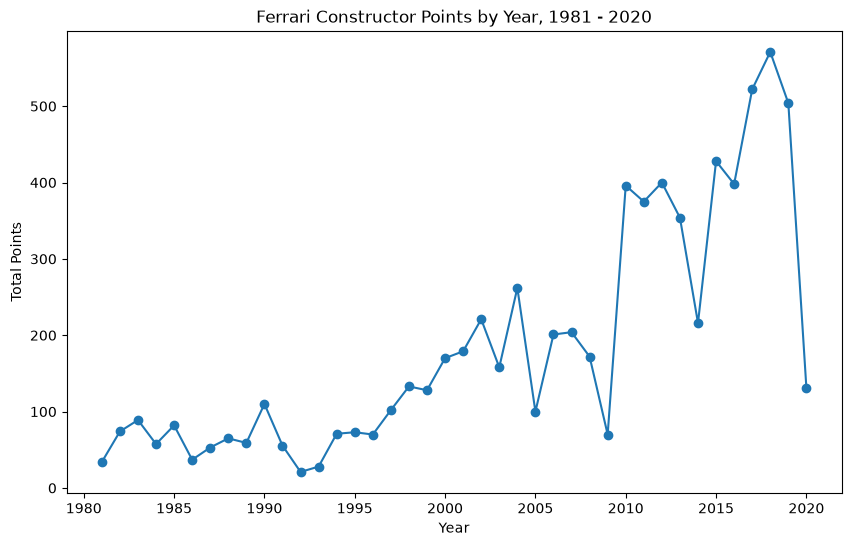

In [80]:
# Graph 

plt.figure(figsize=(10, 6))

plt.plot(
    ferrari_trend["year"],
    ferrari_trend["points"],
    marker="o"
)

plt.title("Ferrari Constructor Points by Year, 1981 - 2020")
plt.xlabel("Year")
plt.ylabel("Total Points")

plt.show()

## New Insight

#### Ferrari's annual constructor points varied considerably between 1981 and 2020. 
The graph shows that point totals were generally higher in the later years of the 
study period, although there were substantial year-to-year fluctuations. Ferrari 
reached its highest annual total in 2018 with 571 points. Points then decreased in 
2019 and dropped sharply in 2020.

This result also rovides additional insight by showing the pattern of Ferrari's 
performance over time rather than focusing only on the single best year.